<a href="https://colab.research.google.com/github/edouardferland-beep/Quant101-2026-2027/blob/main/Rendements_Volatilite_Correlation_Markowitz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Préparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import yfinance as yf

COULEURS = ["#2E86AB", "#E4572E", "#3BB273", "#F2A541"]
plt.rcParams.update({
    "figure.figsize": (14, 7),
    "font.size": 13,
    "axes.titlesize": 17,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=COULEURS),
})

def pourcent(axes="y", ax=None):
    """Affiche l'axe x et/ou y en %."""
    ax = ax or plt.gca()
    if "x" in axes: ax.xaxis.set_major_formatter(PercentFormatter(1))
    if "y" in axes: ax.yaxis.set_major_formatter(PercentFormatter(1))

JOURS_PAR_AN = 252   # jours de bourse par année
RF = 0.03            # taux sans risque annuel (3 %)
np.random.seed(0)    # mêmes résultats à chaque exécution

In [ ]:
actions = ["AAPL", "JPM", "MSFT", "XOM"]
prix = yf.download(actions, period="5y", auto_adjust=True, progress=False)["Close"][actions].dropna()
prix.tail()

Ticker,AAPL,JPM,MSFT,XOM
Date,,,,
2026-10-14,342.959991,335.279999,533.690002,177.009995
2026-10-15,342.000000,335.529999,539.440002,174.679993
2026-10-16,343.459991,339.720001,529.049988,178.979996
2026-10-19,342.940002,333.529999,533.520020,178.279999
2026-10-20,339.500000,335.260010,531.869995,177.860001


## 1. Les prix

<Axes: title={'center': 'Prix des actions'}, xlabel='Date', ylabel='Prix ($)'>

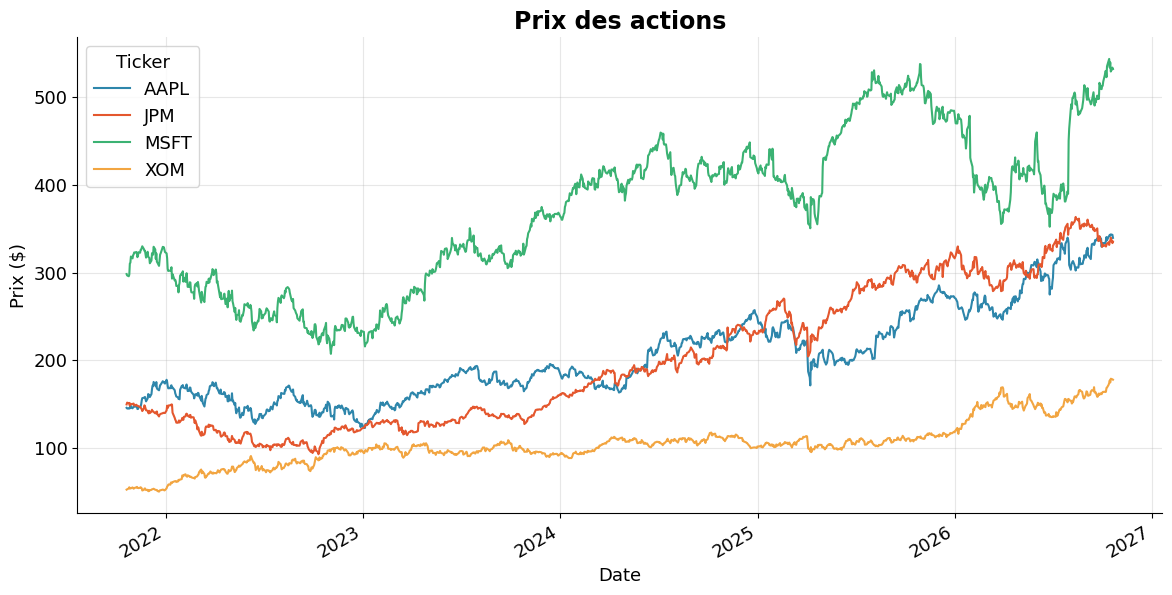

In [ ]:
prix.plot(title="Prix des actions", xlabel="Date", ylabel="Prix ($)")

Les prix ne sont pas comparables, on va plutôt regarder **ce que devient 1 $ investi**.

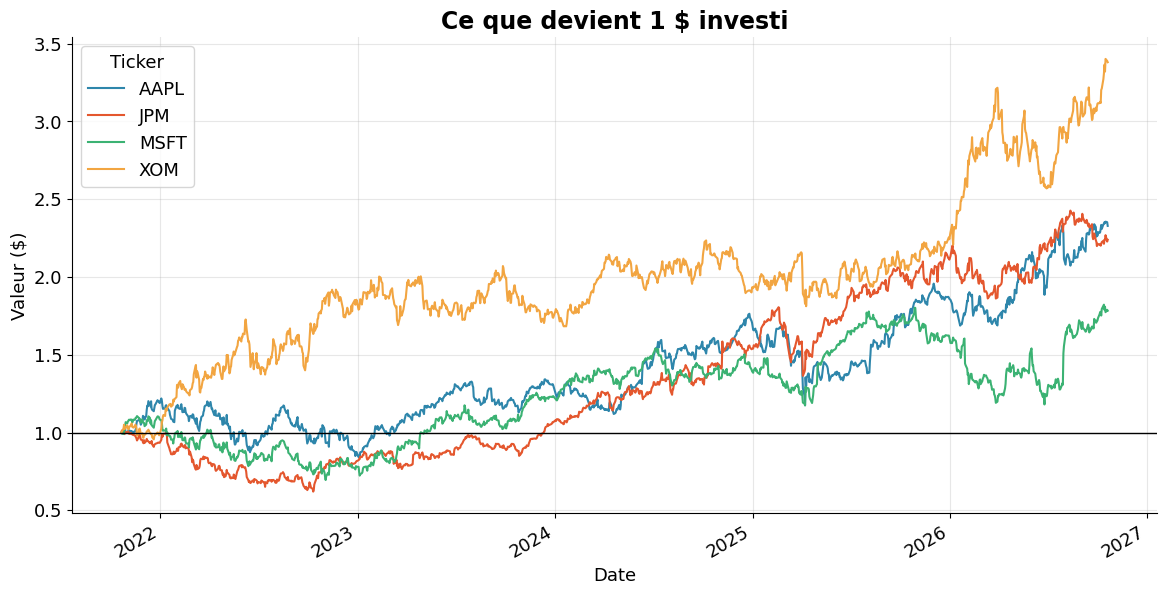

In [ ]:
croissance = prix / prix.iloc[0]
croissance.plot(title="Ce que devient 1 $ investi", xlabel="Date", ylabel="Valeur ($)")
plt.axhline(1, color="black", linewidth=1)

## 2. Rendements

Le rendement est la valeur qui décrit vraiment la croissance d'une action

$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$

Exemple : le prix passe de 100 à 105 → $R = \frac{105 - 100}{100} = +5\,\%$

In [ ]:
rendements = prix.pct_change().dropna()
rendements.head()

Ticker,AAPL,JPM,MSFT,XOM
Date,,,,
2021-10-22,-0.005285,0.013451,-0.005148,0.006859
2021-10-25,-0.000336,-0.004890,-0.003331,0.019487
2021-10-26,0.004575,0.002691,0.006426,0.023155
2021-10-27,-0.003148,-0.020829,0.042114,-0.025972
2021-10-28,0.024992,0.015075,0.003651,0.002807


En quant, lorsqu'on souhaite investir dans un actif, il ne faut pas seulement considérer la croissance passée, il faut considérer comment les rendements évoluent chaque jour.

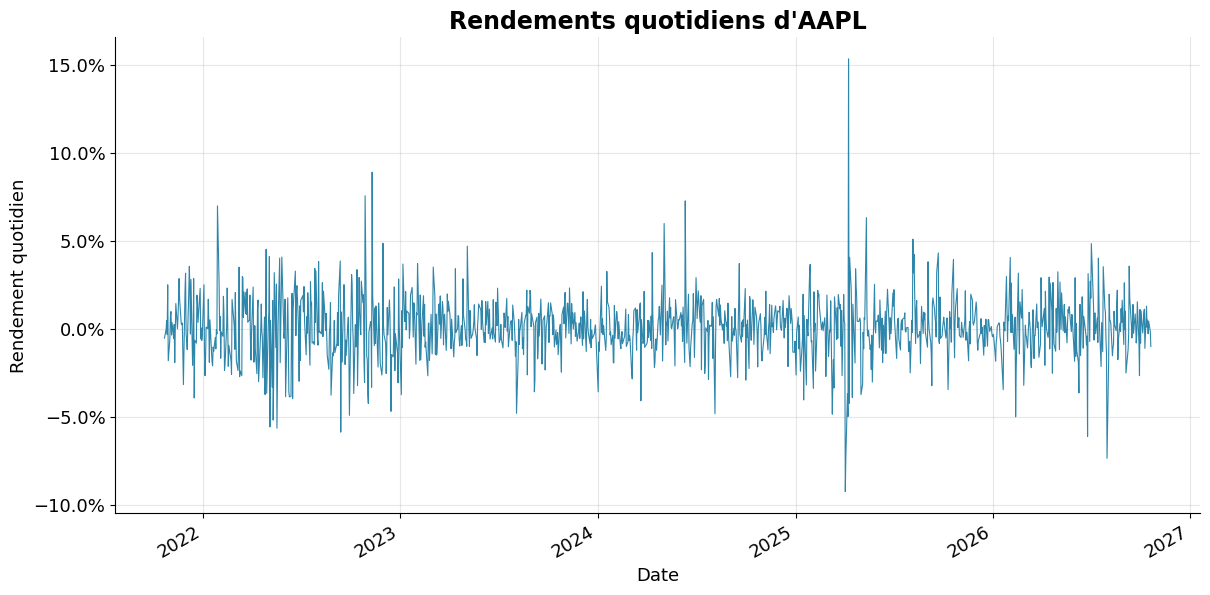

In [ ]:
rendements["AAPL"].plot(title="Rendements quotidiens d'AAPL", xlabel="Date", ylabel="Rendement quotidien", linewidth=0.8)
pourcent()

Pour concrétiser ce graphique nous allons créer une distribution des rendements.

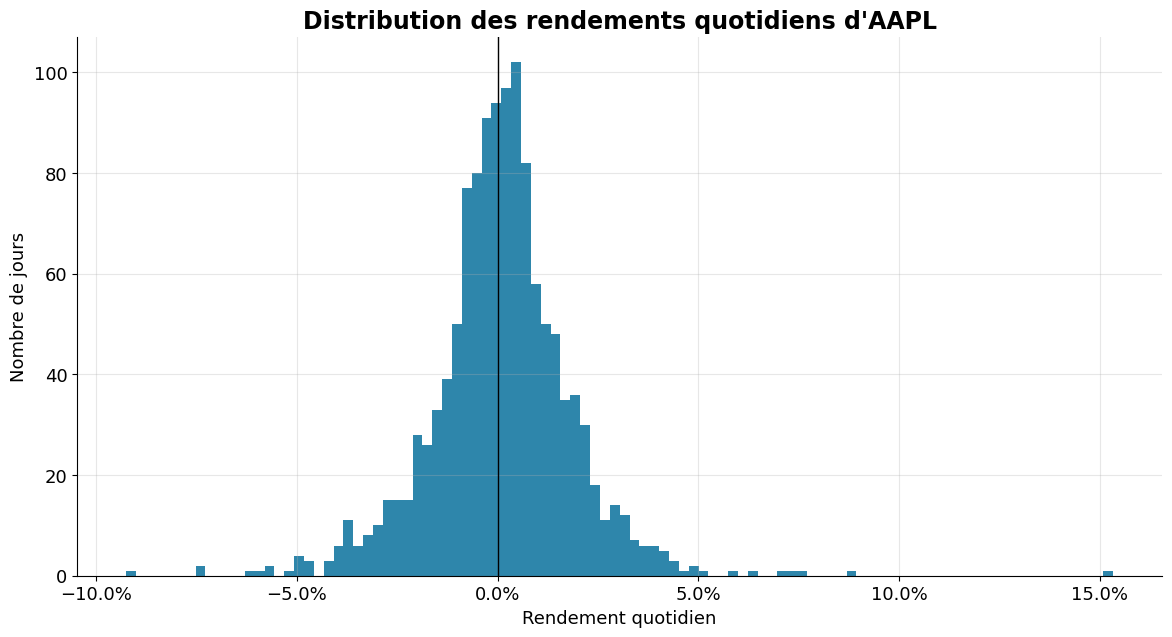

In [ ]:
plt.hist(rendements["AAPL"], bins=100, color=COULEURS[0])
plt.axvline(0, color="black", linewidth=1)
plt.title("Distribution des rendements quotidiens d'AAPL")
plt.xlabel("Rendement quotidien")
plt.ylabel("Nombre de jours")
pourcent("x")

On remarque que la plupart des jours, le prix bouge peu. Quelques fois, il bouge beaucoup (dans les tails).

## 3. Log-rendements

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) = \ln(1 + R_t)$$

**Pourquoi ?** Les rendements simples ne s'additionnent pas dans le temps. Les log-rendements, oui.

Par exemple, un rendement de 10% suivit d'un de -10% ne rammène pas le prix de l'actif à sa valeur initiale.

In [ ]:
print(f"Somme des rendements simples :      {0.10 + (-0.10):+.2%}   ← faux")
print(f"Vrai résultat (100 $ → 110 $ → 99 $) : {1.10 * 0.90 - 1:+.2%}")
print(f"exp(somme des log-rendements) − 1 : {np.exp(np.log(1.10) + np.log(0.90)) - 1:+.2%}   ← exact")

Somme des rendements simples :      +0.00%   ← faux
Vrai résultat (100 $ → 110 $ → 99 $) : -1.00%
exp(somme des log-rendements) − 1 : -1.00%   ← exact


In [ ]:
log_rendements = np.log(prix / prix.shift(1)).dropna()
log_rendements.head()

Ticker,AAPL,JPM,MSFT,XOM
Date,,,,
2021-10-22,-0.005299,0.013362,-0.005162,0.006836
2021-10-25,-0.000336,-0.004902,-0.003337,0.019299
2021-10-26,0.004564,0.002687,0.006405,0.022891
2021-10-27,-0.003153,-0.021049,0.041252,-0.026315
2021-10-28,0.024684,0.014962,0.003645,0.002803


Avant d'utiliser ces valeurs, nous allons comparer une valeur de rendement à son rendement-log associé pour vérifier que l'approximation est valide.

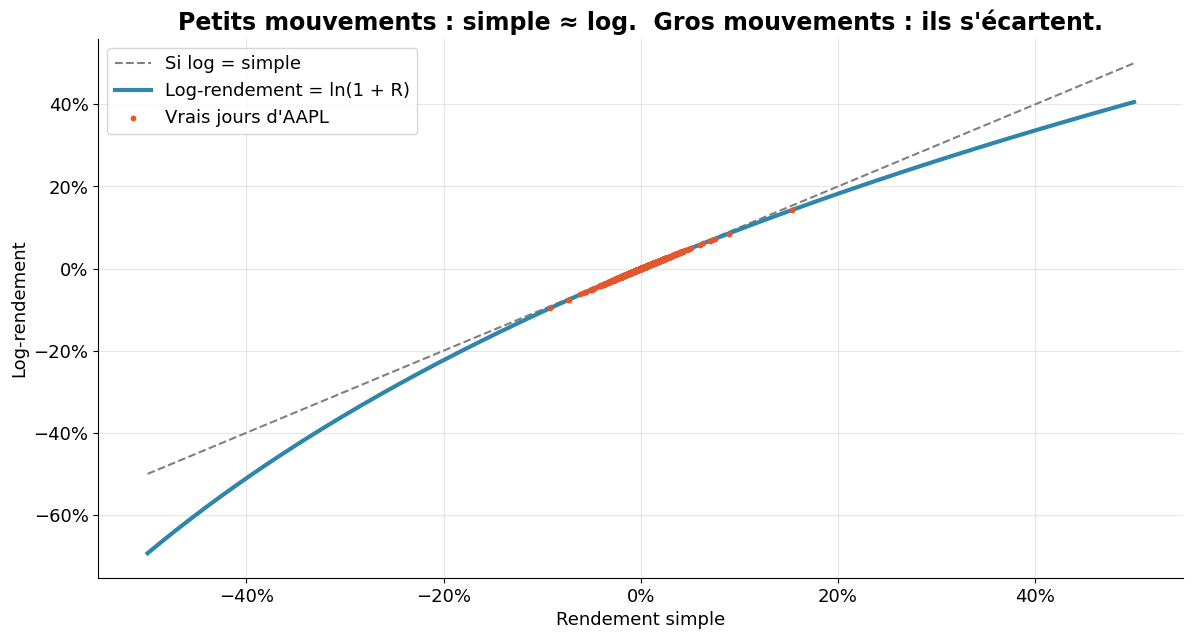

In [ ]:
R = np.linspace(-0.5, 0.5, 200)
plt.plot(R, R, "--", color="gray", label="Si log = simple")
plt.plot(R, np.log(1 + R), linewidth=3, label="Log-rendement = ln(1 + R)")
plt.scatter(rendements["AAPL"], log_rendements["AAPL"], s=10, color=COULEURS[1], zorder=3, label="Vrais jours d'AAPL")
plt.title("Petits mouvements : simple ≈ log.  Gros mouvements : ils s'écartent.")
plt.xlabel("Rendement simple")
plt.ylabel("Log-rendement")
pourcent("xy")
plt.legend()

**Preuve :** additionner les log-rendements puis appliquer $e^x$ redonne exactement la croissance réelle.

$$\sum_t r_t = \ln\frac{P_T}{P_0} \quad\Rightarrow\quad e^{\sum_t r_t} = \frac{P_T}{P_0}$$

On peut aussi vérifier que dans le temps, l'approximation ne dévie pas la trajectoire des rendements d'un actif.

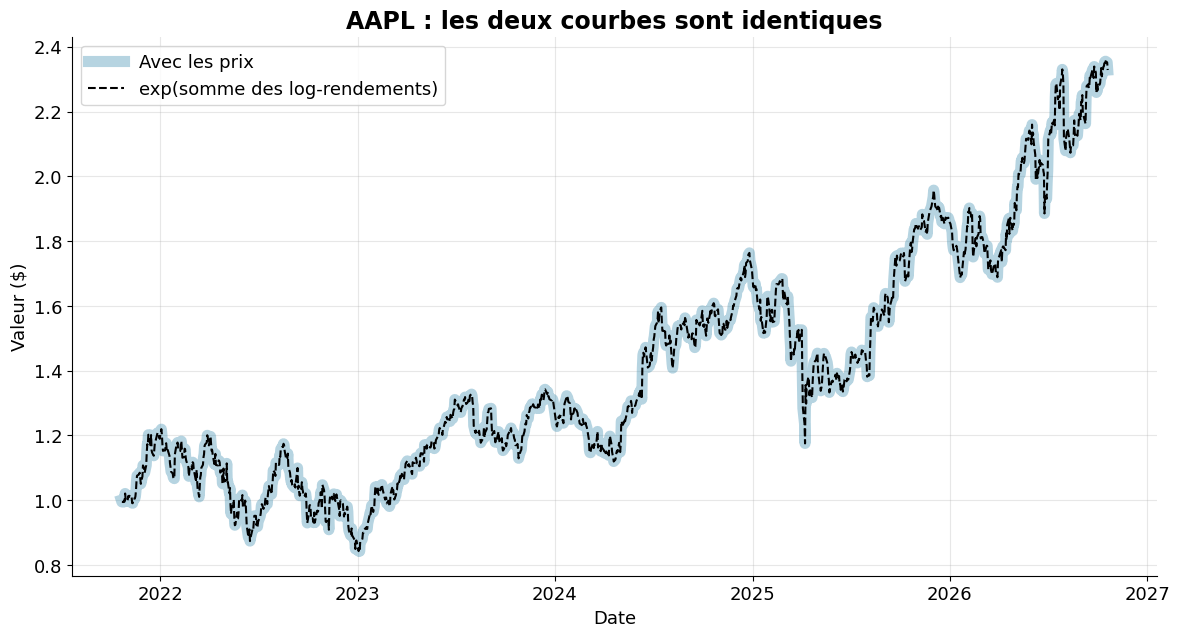

In [ ]:
plt.plot(croissance["AAPL"], linewidth=8, alpha=0.35, label="Avec les prix")
plt.plot(np.exp(log_rendements["AAPL"].cumsum()), "--", color="black", label="exp(somme des log-rendements)")
plt.title("AAPL : les deux courbes sont identiques")
plt.xlabel("Date")
plt.ylabel("Valeur ($)")
plt.legend()

## 4. Volatilité

La volatilité $\sigma$ = l'**écart-type** des rendements-log. Elle mesure le **risque** : à quel point ça bouge.

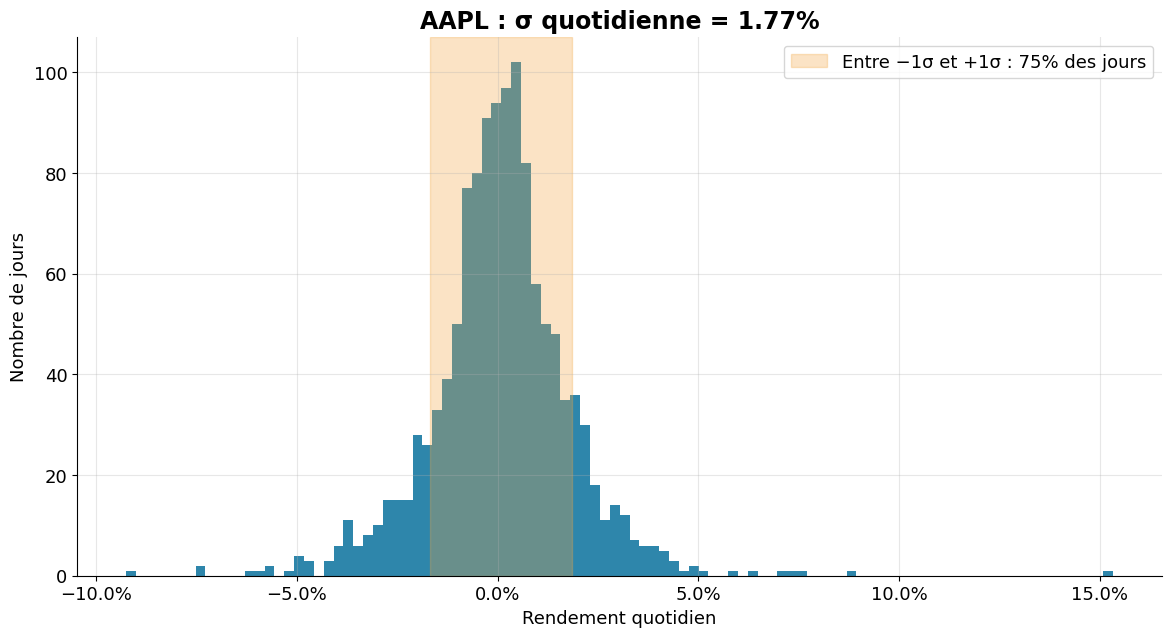

In [ ]:
r = rendements["AAPL"]
moy, sigma = r.mean(), r.std()
part = ((r > moy - sigma) & (r < moy + sigma)).mean()

plt.hist(r, bins=100, color=COULEURS[0])
plt.axvspan(moy - sigma, moy + sigma, color=COULEURS[3], alpha=0.3, label=f"Entre −1σ et +1σ : {part:.0%} des jours")
plt.title(f"AAPL : σ quotidienne = {sigma:.2%}")
plt.xlabel("Rendement quotidien")
plt.ylabel("Nombre de jours")
pourcent("x")
plt.legend()

Il est peu pertinent de prendre la volatilité chaque jour car cela n'est pas représentatif de comportement au long terme. Ainsi, on peut calculer la volatilité annuelle.

$$\sigma_{\text{annuelle}} = \sigma_{\text{quotidienne}} \times \sqrt{252}$$

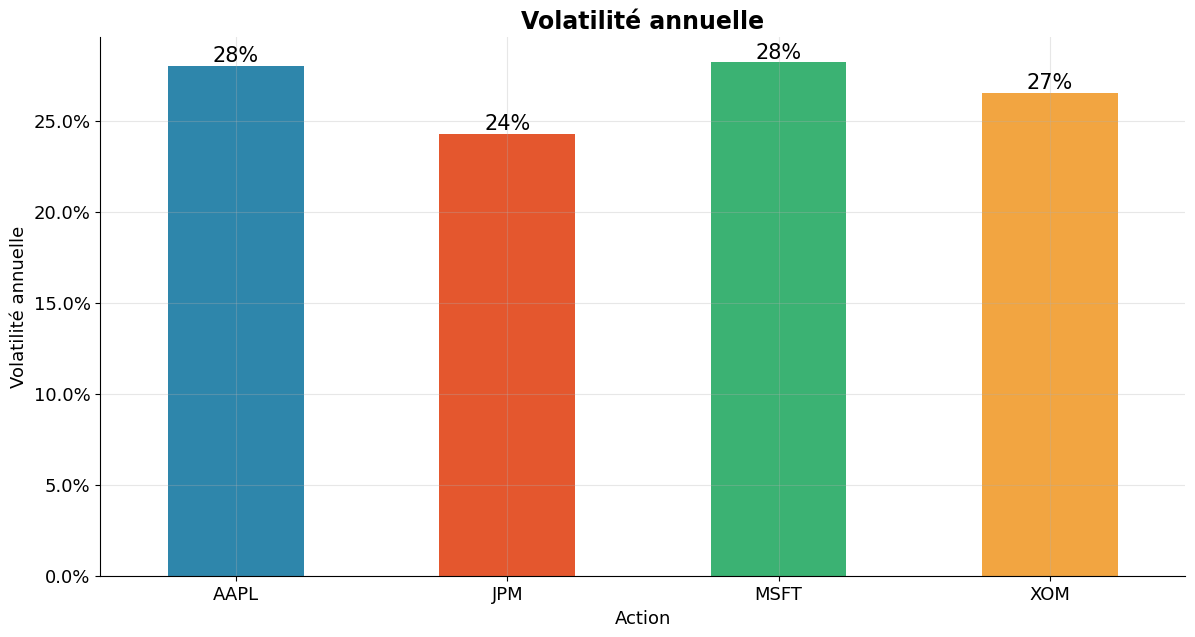

In [ ]:
vol_quotidienne = rendements.std()
vol_annuelle = vol_quotidienne * np.sqrt(JOURS_PAR_AN)

vol_annuelle.plot(kind="bar", color=COULEURS, rot=0, title="Volatilité annuelle", xlabel="Action", ylabel="Volatilité annuelle")
for i, v in enumerate(vol_annuelle):
    plt.text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=15)
pourcent()

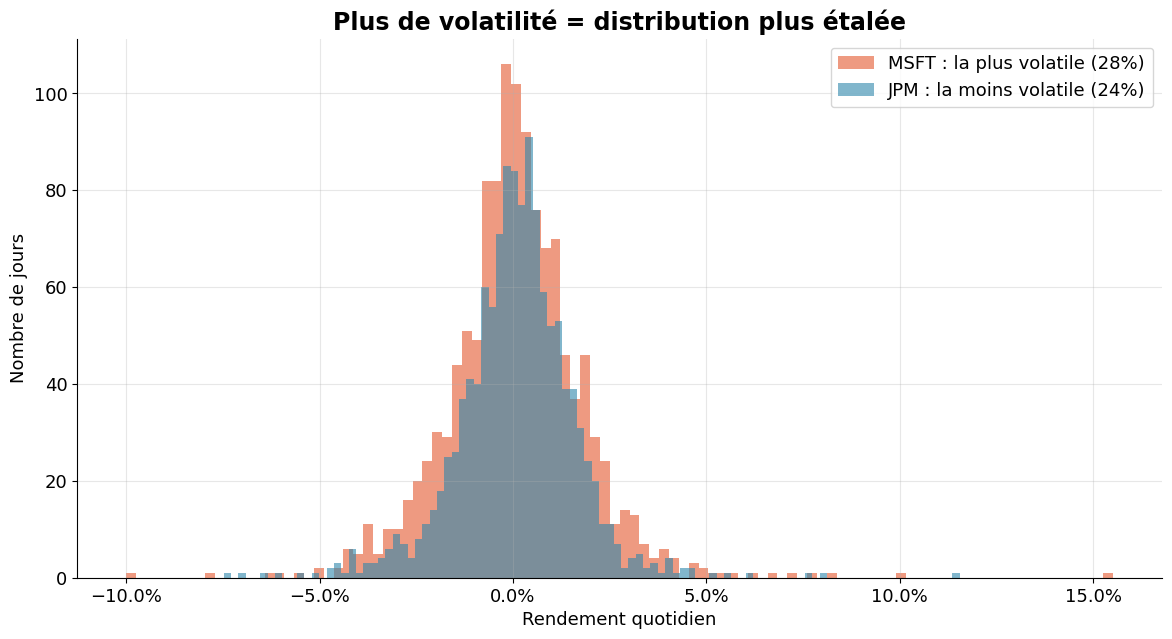

In [ ]:
plus, moins = vol_annuelle.idxmax(), vol_annuelle.idxmin()
plt.hist(rendements[plus], bins=100, alpha=0.6, color=COULEURS[1], label=f"{plus} : la plus volatile ({vol_annuelle[plus]:.0%})")
plt.hist(rendements[moins], bins=100, alpha=0.6, color=COULEURS[0], label=f"{moins} : la moins volatile ({vol_annuelle[moins]:.0%})")
plt.title("Plus de volatilité = distribution plus étalée")
plt.xlabel("Rendement quotidien")
plt.ylabel("Nombre de jours")
pourcent("x")
plt.legend()

Maintenant qu'on est en mesure de modéliser les rendements et la volatilité d'un actif, on voir comment on peut utiliser ces valeurs pour modéliser le comportement d'un portfolio.

## 5. Corrélation

$$\rho_{A,B} = \frac{\text{Cov}(R_A, R_B)}{\sigma_A \, \sigma_B}$$

| ρ | Signification |
|---|---|
| +1 | bougent toujours dans le même sens |
| 0 | aucun lien |
| −1 | bougent toujours en sens opposé |

Faible corrélation = quand une action baisse, l'autre ne baisse pas forcément → **diversification**.

On peut visualiser ce que cela implique Pour des actifs très corrélés.

<Axes: title={'center': 'Prix des actions'}, xlabel='Date', ylabel='Prix ($)'>

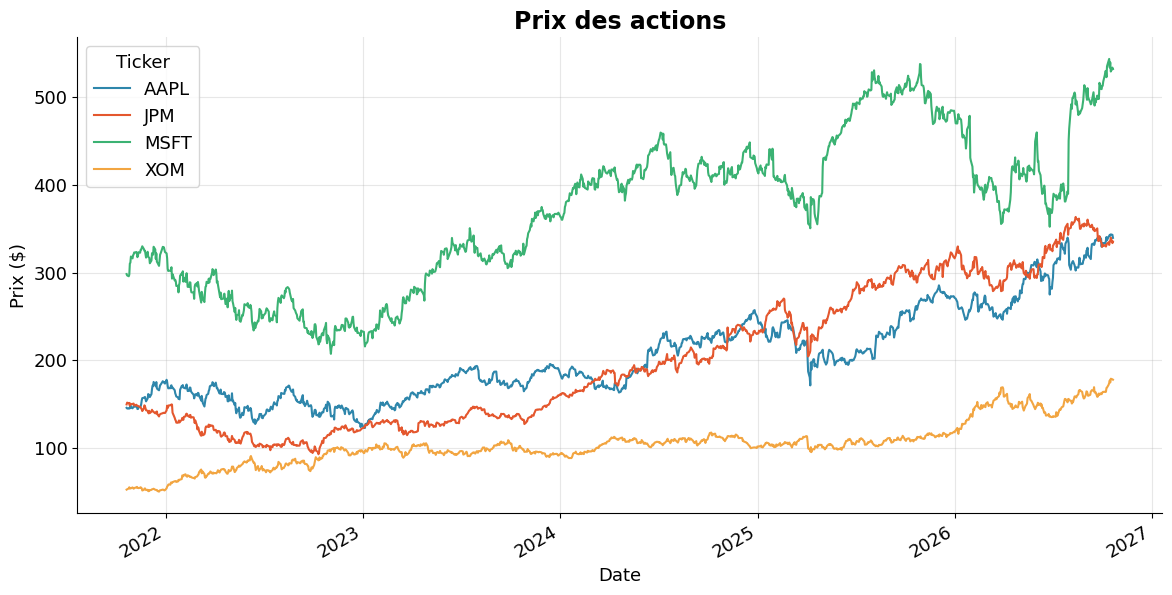

In [ ]:
prix.plot(title="Prix des actions", xlabel="Date", ylabel="Prix ($)")

On peut quantifier cela avec une matrice de corrélation.

Text(0, 0.5, 'Action')

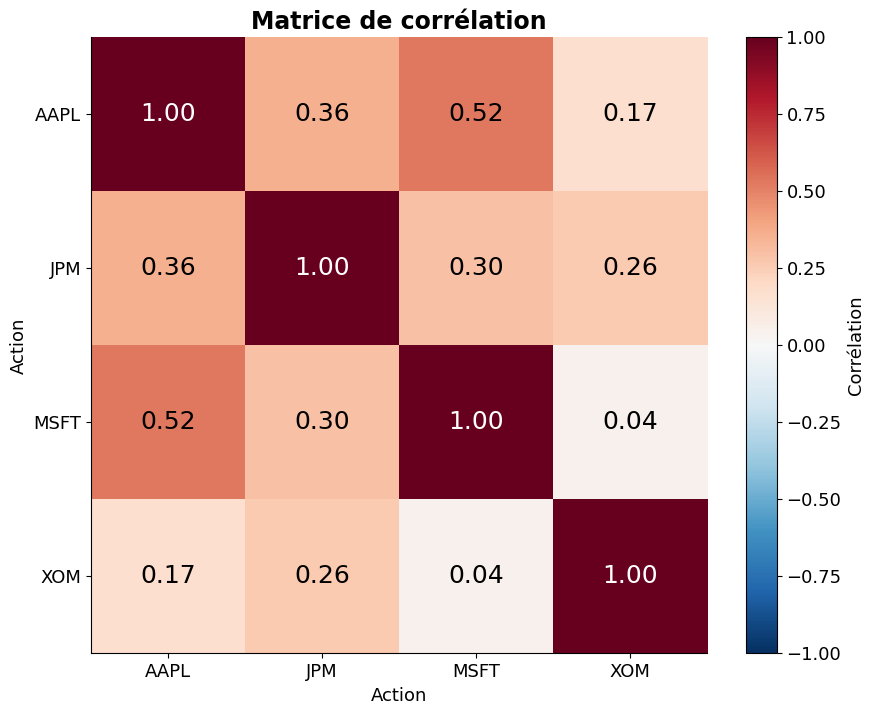

In [ ]:
corr = rendements.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(actions)):
    for j in range(len(actions)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=18,
                 color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
plt.xticks(range(len(actions)), actions)
plt.yticks(range(len(actions)), actions)
plt.grid(False)
plt.colorbar(label="Corrélation")
plt.title("Matrice de corrélation")
plt.xlabel("Action")
plt.ylabel("Action")

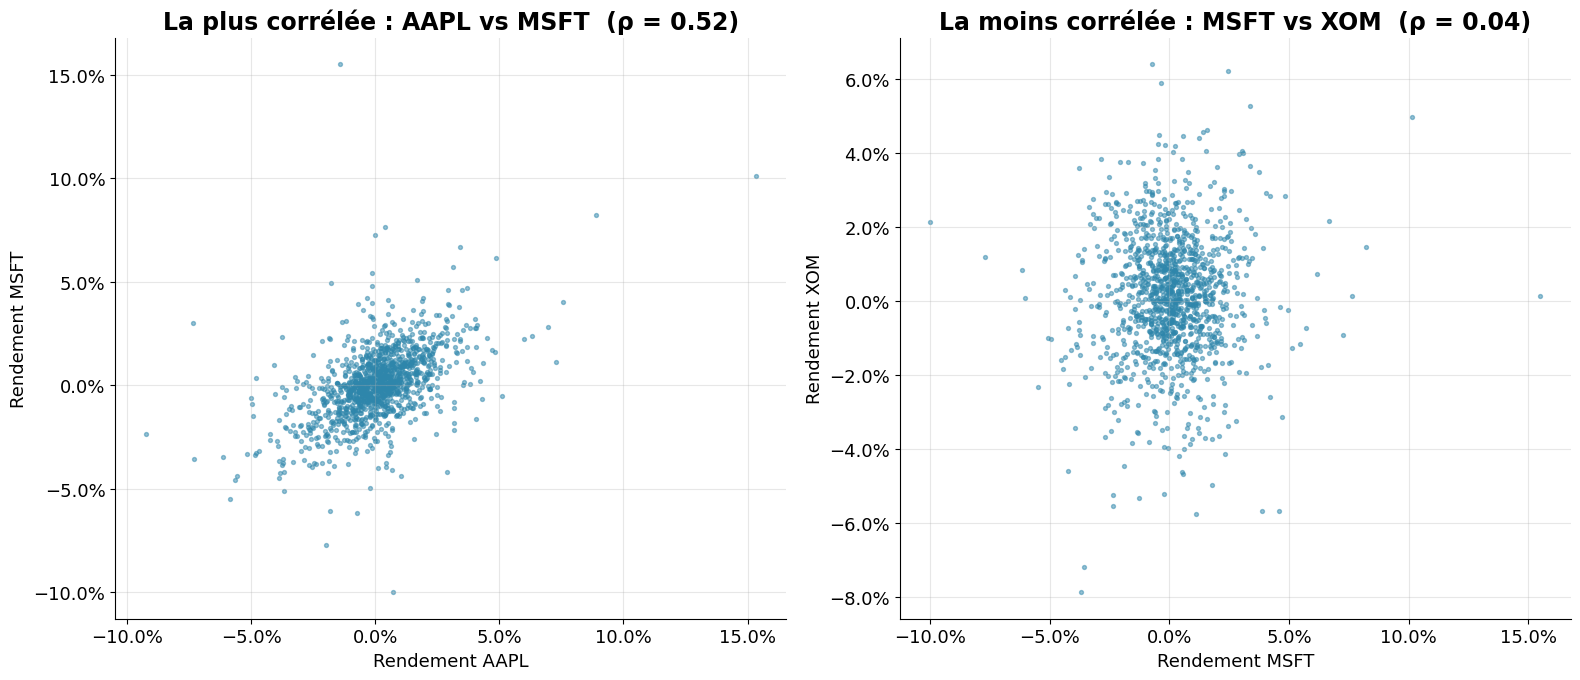

In [ ]:
# On compare automatiquement la paire la plus corrélée et la moins corrélée
paires = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
haute, basse = paires.idxmax(), paires.idxmin()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (a, b), titre in zip(axes, [haute, basse], ["La plus corrélée", "La moins corrélée"]):
    ax.scatter(rendements[a], rendements[b], s=8, alpha=0.5)
    ax.set_title(f"{titre} : {a} vs {b}  (ρ = {corr.loc[a, b]:.2f})")
    ax.set_xlabel(f"Rendement {a}")
    ax.set_ylabel(f"Rendement {b}")
    pourcent("xy", ax)
plt.tight_layout()

Forte corrélation : les points forment une **ligne**. Faible corrélation : un **nuage rond**.

## 6. Rendements attendus

On définit les rendements attendus comme leur espérance.
$$μ=\mathbb{E}[r]$$
Dans notre cas, on considère que les rendements journaliers sont équiprobables.
$$μ=\overline{r}=\frac{∑_i^nr_i}{n}$$
C'est le calcul de la moyenne des rendements.

Cette formule s'étend pour avoir les rendements attendus d'un portfolio $(P)$, où $w_i$ est l'allocation de l'actif $i$ dans le portfolio.
$$\mathbb{E}[\mu_P]=∑_i^Nw_i\mu_i=∑_i^Nw_i\mathbb{E}[r_i]$$

## 7. Markowitz

Un portefeuille = des **poids** $w$ (ex. 60 % AAPL, 40 % XOM), qui totalisent 100 %.

$$\text{Rendement} = \mathbb{E}[P]$$ $$\text{Risque} = σ_P= \sqrt{\sum_i^N\sum_j^Nw_iw_j\sigma_{ij}}$$



Nous allons convertir ces valeurs de rendements et volatilité par jour en rendements annuels et volatilité par année.

In [ ]:
mu = rendements.mean() * JOURS_PAR_AN    # rendement annuel moyen
cov = rendements.cov() * JOURS_PAR_AN     # covariance annuelle

On va essayer de visualiser comment ces rendements et volatilités évoluent en fonction des poids de deux actifs

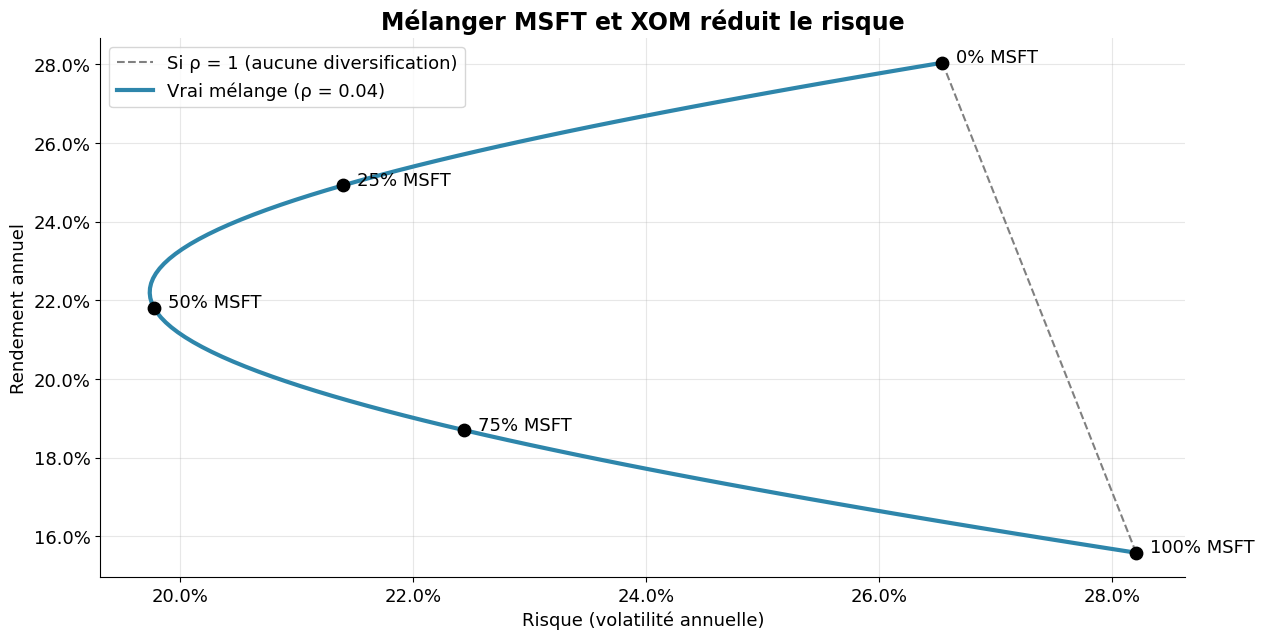

In [ ]:
a, b = basse    # la paire la moins corrélée (section 5)
x = np.linspace(0, 1, 101)    # part de a dans le portefeuille
rend_melange = x * mu[a] + (1 - x) * mu[b]
risque_melange = np.sqrt(x**2 * cov.loc[a, a] + (1 - x)**2 * cov.loc[b, b] + 2 * x * (1 - x) * cov.loc[a, b])
risque_sans_diversification = x * np.sqrt(cov.loc[a, a]) + (1 - x) * np.sqrt(cov.loc[b, b])

plt.plot(risque_sans_diversification, rend_melange, "--", color="gray", label="Si ρ = 1 (aucune diversification)")
plt.plot(risque_melange, rend_melange, linewidth=3, label=f"Vrai mélange (ρ = {corr.loc[a, b]:.2f})")
for p in [0, 0.25, 0.5, 0.75, 1]:
    i = round(p * 100)
    plt.scatter(risque_melange[i], rend_melange[i], s=80, color="black", zorder=3)
    plt.annotate(f"{p:.0%} {a}", (risque_melange[i], rend_melange[i]), xytext=(10, 0), textcoords="offset points")
plt.title(f"Mélanger {a} et {b} réduit le risque")
plt.xlabel("Risque (volatilité annuelle)")
plt.ylabel("Rendement annuel")
pourcent("xy")
plt.legend()

### 5 000 portefeuilles aléatoires avec les 4 actions

In [ ]:
poids, rends, risques = [], [], []
for _ in range(5000):
    w = np.random.random(len(actions))
    w = w / w.sum()                      # les poids totalisent 100 %
    poids.append(w)
    rends.append(w @ mu)
    risques.append(np.sqrt(w @ cov @ w))
poids, rends, risques = np.array(poids), np.array(rends), np.array(risques)

sharpes = (rends - RF) / risques
meilleur = sharpes.argmax()
moins_risque = risques.argmin()

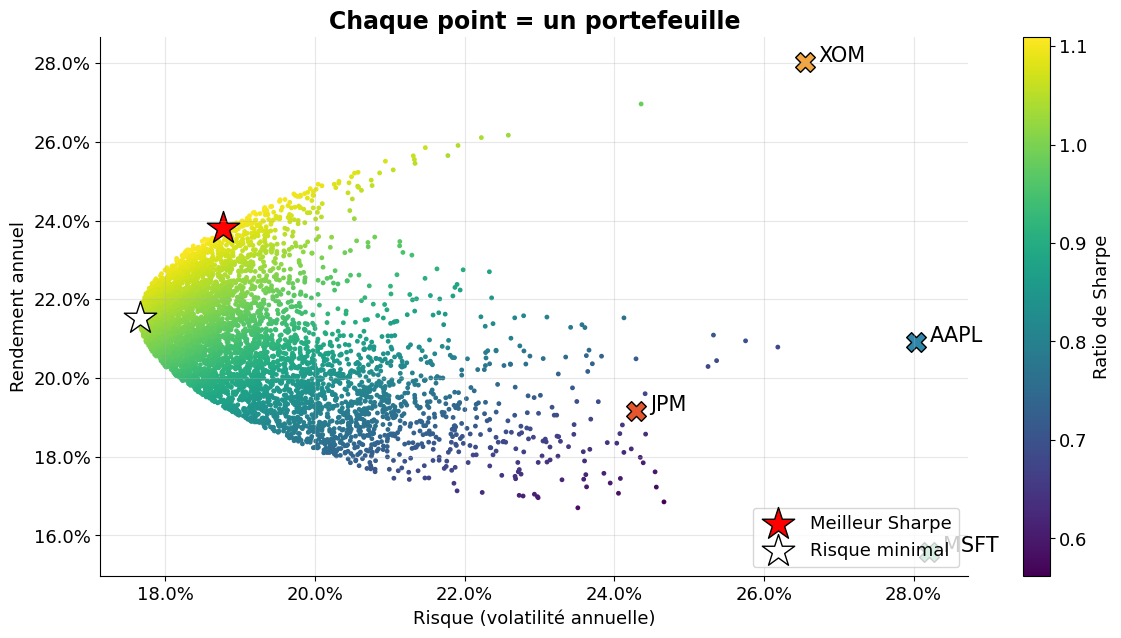

In [ ]:
plt.scatter(risques, rends, c=sharpes, cmap="viridis", s=6)
plt.colorbar(label="Ratio de Sharpe")
plt.scatter(risques[meilleur], rends[meilleur], marker="*", s=600, color="red", edgecolor="black", label="Meilleur Sharpe")
plt.scatter(risques[moins_risque], rends[moins_risque], marker="*", s=600, color="white", edgecolor="black", label="Risque minimal")
for i, t in enumerate(actions):
    plt.scatter(np.sqrt(cov.loc[t, t]), mu[t], marker="X", s=200, color=COULEURS[i], edgecolor="black")
    plt.annotate(t, (np.sqrt(cov.loc[t, t]), mu[t]), xytext=(10, 0), textcoords="offset points", fontsize=15)
plt.title("Chaque point = un portefeuille")
plt.xlabel("Risque (volatilité annuelle)")
plt.ylabel("Rendement annuel")
pourcent("xy")
plt.legend(loc="lower right")

Le **bord gauche** du nuage est la **frontière efficiente** : le meilleur rendement possible pour chaque niveau de risque. Tout point en dessous est inefficace.

On va introduire certaines mesures de performance du portfolio pour mieux expliquer ce nuage de points.

## 8. Sharpe et Sortino

$$\text{Sharpe} = \frac{R - R_f}{\sigma} \qquad \text{Sortino} = \frac{R - R_f}{\sigma_{\text{baisse}}}$$

- $R_f$ = taux sans risque (ce qu'on gagne sans prendre de risque, ici 3 %)
- **Sharpe** : rendement en plus par unité de risque **total**
- **Sortino** : pareil, mais ne pénalise que les **baisses** (les hausses ne sont pas un « risque »)

Plus c'est élevé, mieux c'est. Au-dessus de 1 = bon.

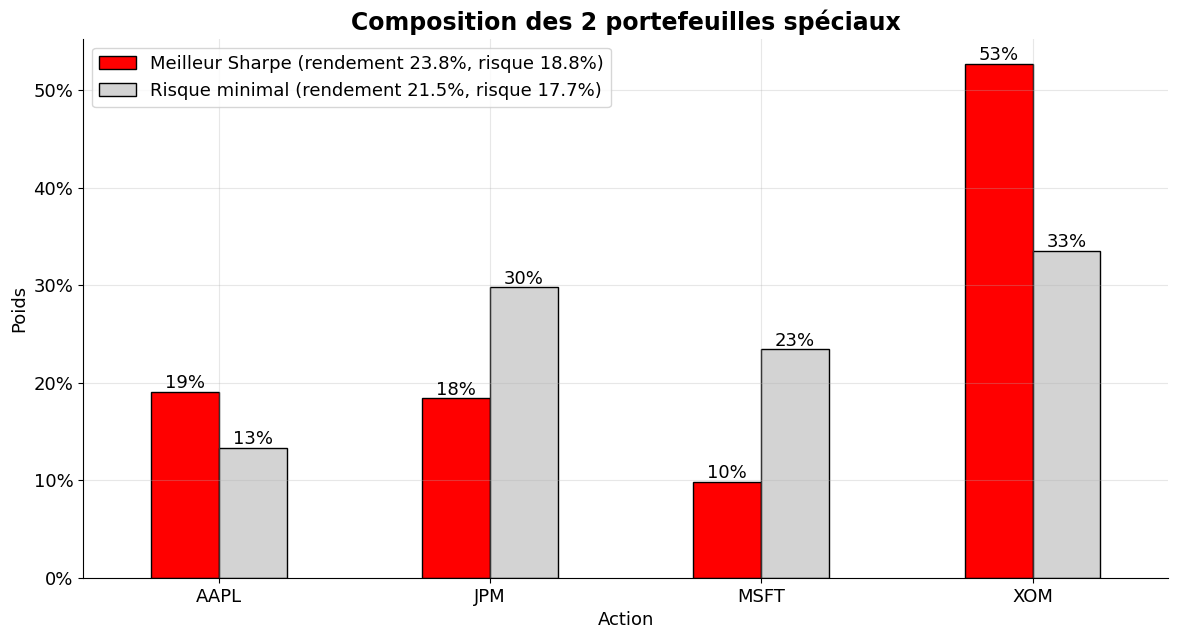

In [ ]:
composition = pd.DataFrame({
    f"Meilleur Sharpe (rendement {rends[meilleur]:.1%}, risque {risques[meilleur]:.1%})": poids[meilleur],
    f"Risque minimal (rendement {rends[moins_risque]:.1%}, risque {risques[moins_risque]:.1%})": poids[moins_risque],
}, index=actions)

ax = composition.plot(kind="bar", rot=0, color=["red", "lightgray"], edgecolor="black",
                      title="Composition des 2 portefeuilles spéciaux", xlabel="Action", ylabel="Poids")
for barres in ax.containers:
    ax.bar_label(barres, labels=[f"{v:.0%}" for v in barres.datavalues], fontsize=13)
pourcent()

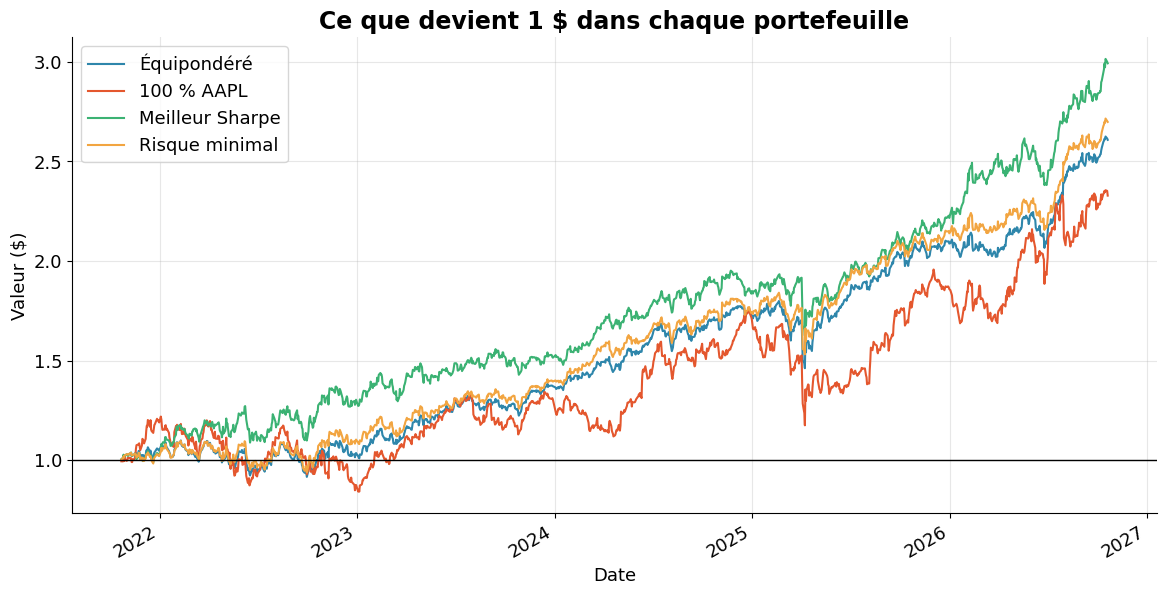

In [ ]:
portefeuilles = {
    "Équipondéré": np.ones(len(actions)) / len(actions),
    "100 % AAPL": np.array([1, 0, 0, 0]),           # ordre : AAPL, JPM, MSFT, XOM
    "Meilleur Sharpe": poids[meilleur],
    "Risque minimal": poids[moins_risque],
}

rend_ptf = pd.DataFrame({nom: rendements @ w for nom, w in portefeuilles.items()})
(1 + rend_ptf).cumprod().plot(title="Ce que devient 1 $ dans chaque portefeuille", xlabel="Date", ylabel="Valeur ($)")
plt.axhline(1, color="black", linewidth=1)

##9. Conclusion de la séance:
Nous avons vu:
- Comment les retours sont calculés et comment on en dérive la volatilité
- Comment quantifier les similitudes entre les mouvements des actifs (corrélations)
- Comment des portfolios sont construits selon le modèle de Markowitz
- Comment calculer les ratios de Sharpe et Sortino

## À venir:
- Introduction aux options, pricing et théorie sur les stratégies
- Modèle de pricing CAPM (Capital Asset Pricing Model) et $α,β$

## 10. Complément sur les ratios de sharpe et sortino des portefeuilles.
Que signifie la volatilité à la baisse?

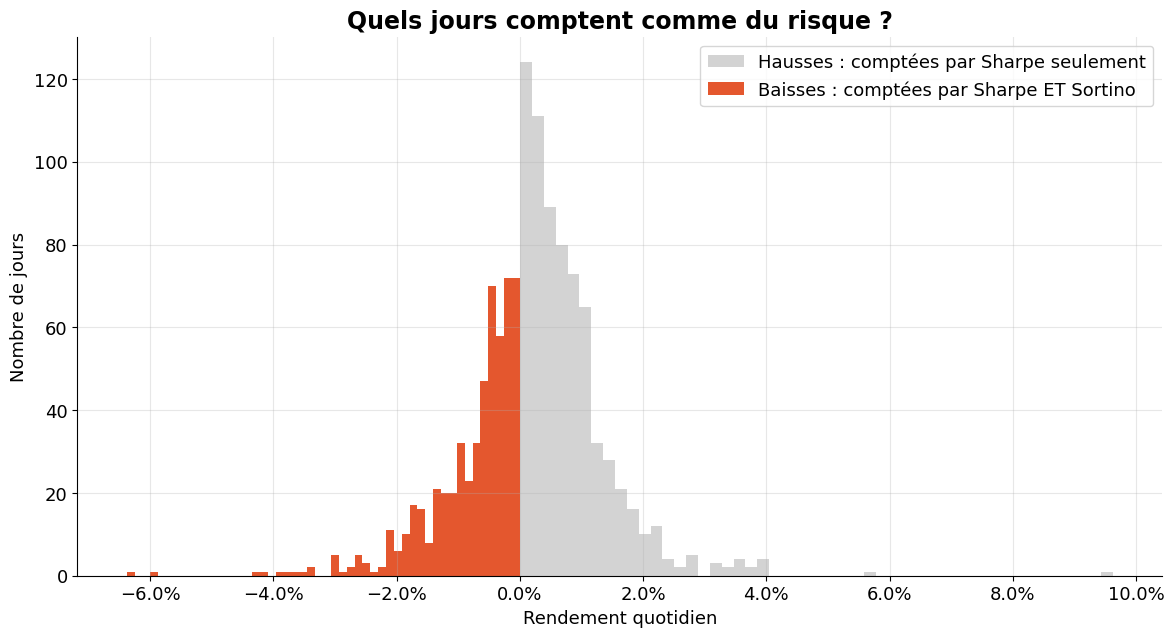

In [ ]:
r = rend_ptf["Équipondéré"]
plt.hist(r[r >= 0], bins=50, color="lightgray", label="Hausses : comptées par Sharpe seulement")
plt.hist(r[r < 0], bins=50, color=COULEURS[1], label="Baisses : comptées par Sharpe ET Sortino")
plt.title("Quels jours comptent comme du risque ?")
plt.xlabel("Rendement quotidien")
plt.ylabel("Nombre de jours")
pourcent("x")
plt.legend()

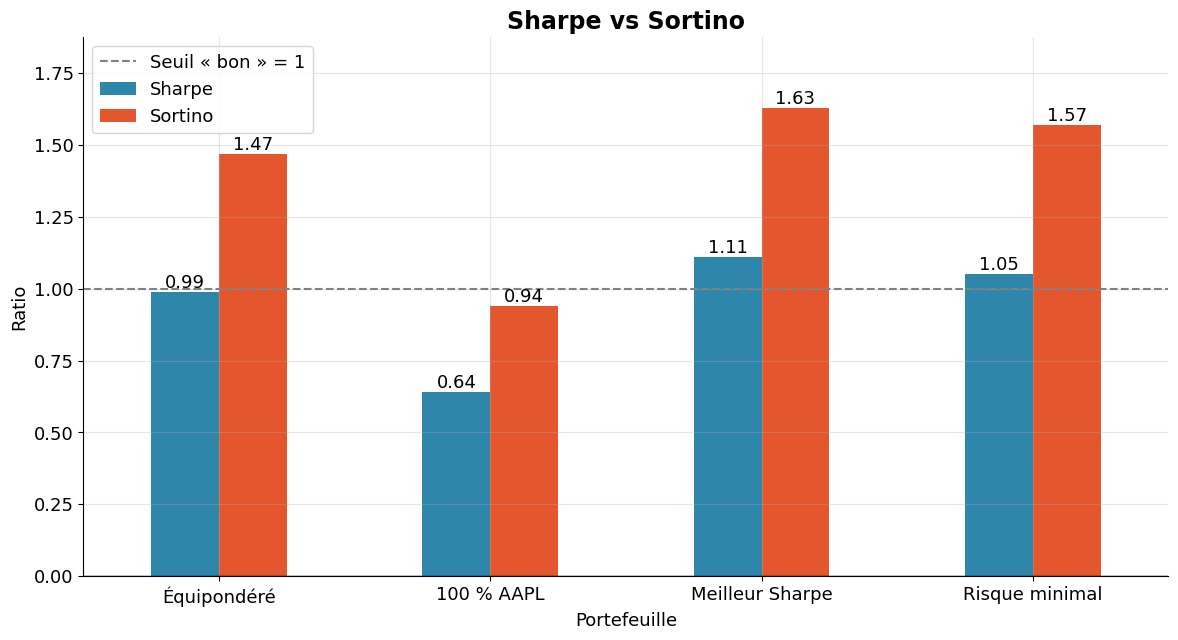

In [ ]:
ax = ratios[["Sharpe", "Sortino"]].plot(kind="bar", rot=0, title="Sharpe vs Sortino", xlabel="Portefeuille", ylabel="Ratio")
for barres in ax.containers:
    ax.bar_label(barres, fmt="%.2f", fontsize=13)
plt.axhline(0, color="black", linewidth=1)
plt.axhline(1, color="gray", linestyle="--", label="Seuil « bon » = 1")
plt.ylim(top=max(1.2, ratios[["Sharpe", "Sortino"]].max().max() * 1.15))
plt.legend()

La différence entre ces deux mesures s'explique par le fait que Sharpe considère qu'un revenu positif extrême constitue un risque, ce qui est souhaité dans le monde de l'investissement. Dans les exemples ici, le sharpe aurait surestimé les vrais risques par rapport à Sortino.

ATTENTION: Le portefeuille « Meilleur Sharpe » a été choisi **avec les mêmes données** que le test. Son score est donc exagéré : rien ne garantit qu'il restera le meilleur dans le futur.